In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import ipywidgets as widgets
from IPython.display import display

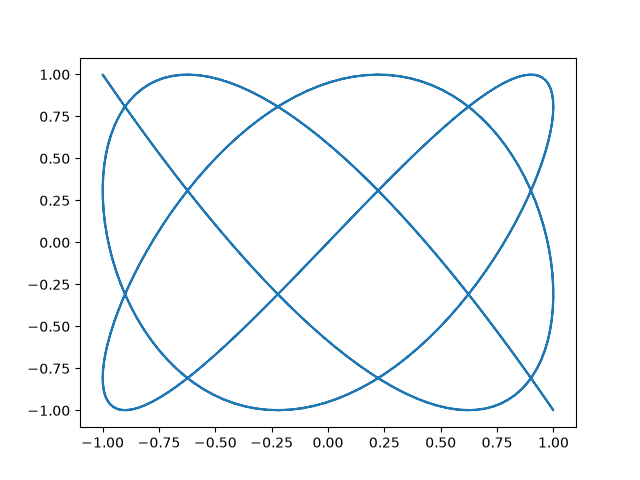

In [3]:
t = np.linspace(0, 2*np.pi, 300)

plt.figure()
plt.plot(np.sin(5*t), np.sin(7*t))

## Interaktivní animace Lissajousových obrazců

Animace zobrazuje Lissajousův obrazec $(x(t), y(t))$ spolu s časovým průběhem obou souřadnic $x(t)$ a $y(t)$. Pomocí posuvníků lze měnit frekvence $a$, $b$ a fázový posun $\delta$.

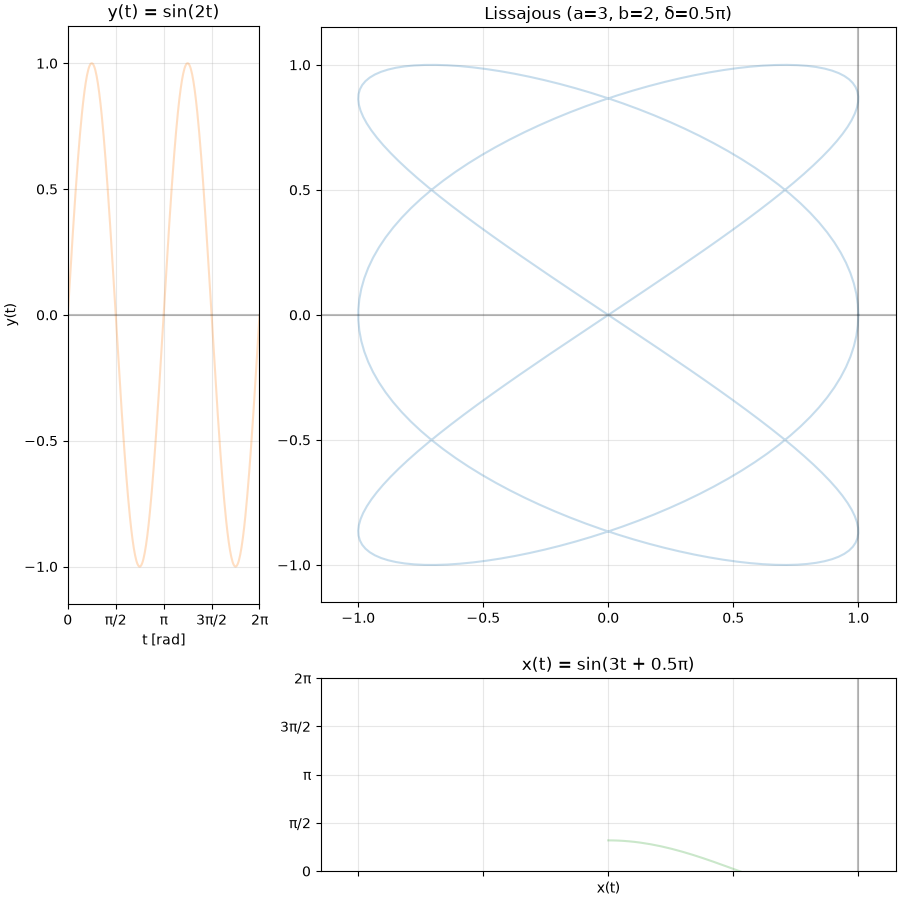

In [2]:
t = np.linspace(0, 2 * np.pi, 300)

state = {
    'a': 3.0,
    'b': 2.0,
    'delta': np.pi / 2,
    'idx': 0,
    'x': None,
    'y': None,
}

def compute_xy():
    state['x'] = np.sin(state['a'] * t + state['delta'])
    state['y'] = np.sin(state['b'] * t)

compute_xy()

plt.close('all')
fig = plt.figure(figsize=(9, 9), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1, 3], height_ratios=[3, 1])

ax_liss = fig.add_subplot(gs[0, 1])
ax_x = fig.add_subplot(gs[1, 1], sharex=ax_liss)
ax_y = fig.add_subplot(gs[0, 0], sharey=ax_liss)

# Lissajous pattern
line_liss_bg, = ax_liss.plot(state['x'], state['y'], color='tab:blue', alpha=0.25, lw=1.5)
line_liss, = ax_liss.plot([], [], color='tab:blue', lw=2)
pt_liss, = ax_liss.plot([], [], 'o', color='tab:red', ms=7, zorder=5)
ax_liss.set_xlim(-1.15, 1.15)
ax_liss.set_ylim(-1.15, 1.15)
ax_liss.set_aspect('equal', adjustable='box')
ax_liss.grid(True, alpha=0.3)

# x(t)
line_x_bg, = ax_x.plot(t, state['x'], color='tab:green', alpha=0.25, lw=1.5)
line_x, = ax_x.plot([], [], color='tab:green', lw=2)
pt_x, = ax_x.plot([], [], 'o', color='tab:red', ms=6, zorder=5)
ax_x.set_ylim(0, 2 * np.pi)
ax_x.set_xlim(-1.15, 1.15)
ax_x.set_xlabel('x(t)')
ax_x.grid(True, alpha=0.3)
plt.setp(ax_x.get_xticklabels(), visible=False)

# y(t)
line_y_bg, = ax_y.plot(t, state['y'], color='tab:orange', alpha=0.25, lw=1.5)
line_y, = ax_y.plot([], [], color='tab:orange', lw=2)
pt_y, = ax_y.plot([], [], 'o', color='tab:red', ms=6, zorder=5)
ax_y.set_xlim(0, 2 * np.pi)
ax_y.set_ylim(-1.15, 1.15)
ax_y.set_xlabel('t [rad]')
ax_y.set_ylabel('y(t)')
ax_y.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
ax_y.set_xticklabels(['0', 'π/2', 'π', '3π/2', '2π'])
ax_y.grid(True, alpha=0.3)

ax_x.set_yticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
ax_x.set_yticklabels(['0', 'π/2', 'π', '3π/2', '2π'])

crosshair_v = ax_liss.axvline(state['x'][0], alpha=0.25, color='k')
crosshair_h = ax_liss.axhline(state['y'][0], alpha=0.25, color='k')
x_v = ax_x.axvline(state['x'][0], alpha=0.25, color='k')
y_h = ax_y.axhline(state['y'][0], alpha=0.25, color='k')

def update_titles():
    ax_liss.set_title(f"Lissajous (a={state['a']:g}, b={state['b']:g}, δ={state['delta']/np.pi:g}π)")
    ax_x.set_title(f"x(t) = sin({state['a']:g}t + {state['delta']/np.pi:g}π)")
    ax_y.set_title(f"y(t) = sin({state['b']:g}t)")

update_titles()

def draw_frame(i):
    x, y = state['x'], state['y']
    line_liss.set_data(x[:i + 1], y[:i + 1])
    pt_liss.set_data([x[i]], [y[i]])
    line_x.set_data(x[:i + 1], t[:i + 1])
    pt_x.set_data([x[i]], [t[i]])
    line_y.set_data(t[:i + 1], y[:i + 1])
    pt_y.set_data([t[i]], [y[i]])
    crosshair_v.set_xdata([x[i], x[i]])
    crosshair_h.set_ydata([y[i], y[i]])
    x_v.set_xdata([x[i], x[i]])
    y_h.set_ydata([y[i], y[i]])

def animate(_frame):
    draw_frame(state['idx'])
    state['idx'] = (state['idx'] + 1) % len(t)
    return line_liss, pt_liss, line_x, pt_x, line_y, pt_y, crosshair_v, crosshair_h, x_v, y_h

anim = FuncAnimation(fig, animate, interval=25, blit=False, cache_frame_data=False)

slider_a = widgets.FloatSlider(value=3.0, min=0.5, max=10.0, step=0.5, description='f_x (a):')
slider_b = widgets.FloatSlider(value=2.0, min=0.5, max=10.0, step=0.5, description='f_y (b):')
slider_delta = widgets.FloatSlider(value=0.5, min=0.0, max=2.0, step=0.25, description='δ / π:')
play_btn = widgets.ToggleButton(value=True, description='Pause', icon='pause')
reset_btn = widgets.Button(description='Restart', icon='refresh')

def on_param_change(_change):
    state['a'] = slider_a.value
    state['b'] = slider_b.value
    state['delta'] = slider_delta.value * np.pi
    compute_xy()
    line_liss_bg.set_data(state['x'], state['y'])
    line_x_bg.set_data(state['x'], t)
    line_y_bg.set_data(t, state['y'])
    update_titles()
    draw_frame(state['idx'])
    fig.canvas.draw_idle()

def on_play_toggle(change):
    if change['new']:
        play_btn.description = 'Pause'
        play_btn.icon = 'pause'
        anim.resume()
    else:
        play_btn.description = 'Play'
        play_btn.icon = 'play'
        anim.pause()

def on_reset(_btn):
    state['idx'] = 0
    draw_frame(0)
    fig.canvas.draw_idle()

slider_a.observe(on_param_change, names='value')
slider_b.observe(on_param_change, names='value')
slider_delta.observe(on_param_change, names='value')
play_btn.observe(on_play_toggle, names='value')
reset_btn.observe(on_reset, names='click')

controls = widgets.VBox([
    widgets.HBox([slider_a, slider_b, slider_delta]),
    widgets.HBox([play_btn, reset_btn]),
])
display(controls)
plt.show()